<a href="https://colab.research.google.com/github/aman05personal05/ComputerVisionTraining/blob/main/week2_classification/day4_augmentation/Week2_Day4_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2 · Day 4 — Data Augmentation with Albumentations
**Ablation Study: Baseline → Spatial → Color → Advanced → Full**

| | |
|---|---|
| **Runtime** | GPU (T4 — free tier) |
| **Estimated time** | ~90–120 min (5 experiments × ~15 min each) |
| **Topics** | Albumentations · Augmentation pipelines · Ablation study · Baseline comparison |

---
### ⚡ Before you start
1. Go to **Runtime → Change runtime type → T4 GPU**
2. Ensure the **Intel Image Classification** dataset is on your Google Drive at:
   `MyDrive/datasets/intel-image-classification/`
3. Run cells top-to-bottom

### 📋 What we'll do today
1. Establish a **no-augmentation baseline** (resize + center crop + normalize only)
2. Build 4 incremental augmentation pipelines using **Albumentations**
3. Run a **controlled ablation study** — same backbone, same LR, same epochs, same split
4. Compare results and build the **ablation table**

> ⚠️ **Critical**: ONLY the training transforms change between experiments. Evaluation transforms are ALWAYS deterministic.

## 0 · Setup & GPU Check

In [29]:
import torch
print(f'PyTorch  : {torch.__version__}')
print(f'CUDA     : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU      : {torch.cuda.get_device_name(0)}')
    print(f'VRAM     : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device   : {DEVICE}')

PyTorch  : 2.11.0+cpu
CUDA     : False
Device   : cpu


In [30]:
!pip install -q albumentations wandb
print('✅ Packages ready')

✅ Packages ready


In [31]:
# Mount Google Drive — dataset + results persistence
from google.colab import drive
drive.mount('/content/drive')

import os

# ── Paths on Google Drive ──────────────────────────────────────
DRIVE_DATA_DIR    = '/content/drive/MyDrive/datasets/intel-image-classification'
DRIVE_RESULTS_DIR = '/content/drive/MyDrive/ComputerVision/week2_classification/results'
DRIVE_MODEL_DIR   = '/content/drive/MyDrive/ComputerVision/week2_classification/models'

os.makedirs(DRIVE_RESULTS_DIR, exist_ok=True)
os.makedirs(DRIVE_MODEL_DIR, exist_ok=True)

# Verify dataset exists
assert os.path.exists(DRIVE_DATA_DIR), (
    f'❌ Dataset not found at {DRIVE_DATA_DIR}\n'
    f'   Upload Intel Image Classification to your Drive at:\n'
    f'   MyDrive/datasets/intel-image-classification/'
)
print(f'Dataset  → {DRIVE_DATA_DIR}')
print(f'Results  → {DRIVE_RESULTS_DIR}')
print(f'Models   → {DRIVE_MODEL_DIR}')
print('✅ Google Drive mounted & paths verified')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset  → /content/drive/MyDrive/datasets/intel-image-classification
Results  → /content/drive/MyDrive/ComputerVision/week2_classification/results
Models   → /content/drive/MyDrive/ComputerVision/week2_classification/models
✅ Google Drive mounted & paths verified


In [32]:
# Copy dataset from Google Drive to local Colab runtime disk for ultra-fast training
import shutil
import os

LOCAL_DATA_DIR = '/content/intel-image-classification'

if not os.path.exists(LOCAL_DATA_DIR):
    print("⚡ Copying dataset to local disk for fast training (this takes ~1-2 mins)... ")
    shutil.copytree(DRIVE_DATA_DIR, LOCAL_DATA_DIR)
    print("✅ Dataset copied locally!")
else:
    print("✅ Dataset already exists locally.")

# Redefine the paths to use the local fast directory
train_root = os.path.join(LOCAL_DATA_DIR, 'seg_train', 'seg_train')
test_root  = os.path.join(LOCAL_DATA_DIR, 'seg_test', 'seg_test')

# Fallback check
if not os.path.exists(train_root):
    train_root = os.path.join(LOCAL_DATA_DIR, 'seg_train')
if not os.path.exists(test_root):
    test_root = os.path.join(LOCAL_DATA_DIR, 'seg_test')

print(f"Local Train path: {train_root}")
print(f"Local Test path:  {test_root}")

✅ Dataset already exists locally.
Local Train path: /content/intel-image-classification/seg_train/seg_train
Local Test path:  /content/intel-image-classification/seg_test/seg_test


## 1 · Imports

In [33]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision
import torchvision.models as models
from torchvision.models import ResNet18_Weights, ResNet50_Weights, EfficientNet_B0_Weights
from torchvision.datasets import ImageFolder
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 110
import numpy as np
from pathlib import Path
from collections import Counter, OrderedDict
import time
import json
import os

import albumentations as A
from albumentations.pytorch import ToTensorV2

try:
    import wandb
    WANDB_AVAILABLE = True
except ImportError:
    WANDB_AVAILABLE = False
    print("wandb not installed -- run: !pip install wandb")

torch.manual_seed(42)
np.random.seed(42)

RESULTS_DIR = DRIVE_RESULTS_DIR
MODEL_DIR   = DRIVE_MODEL_DIR

# ImageNet stats — backbone was pretrained on ImageNet
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

print('✅ Imports done')

✅ Imports done


## 2 · Dataset Discovery & Quick Stats

In [34]:
from pathlib import Path

train_dir = Path(train_root)
test_dir  = Path(test_root)

class_names = sorted([d.name for d in train_dir.iterdir() if d.is_dir()])
num_classes = len(class_names)

# Quick count
train_total = sum(len(list((train_dir / cls).glob('*'))) for cls in class_names)
test_total  = sum(len(list((test_dir / cls).glob('*'))) for cls in class_names)

print(f'✅ Dataset ready')
print(f'   Classes ({num_classes}): {class_names}')
print(f'   Train: {train_total:,} images')
print(f'   Test:  {test_total:,} images')

✅ Dataset ready
   Classes (6): ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
   Train: 14,035 images
   Test:  3,001 images


## 3 · Augmentation Pipelines

We build **5 augmentation pipelines** for the ablation study:

| # | Name | Augmentations | Purpose |
|---|------|---------------|--------|
| 1 | **baseline** | None (resize + center crop) | Controlled reference |
| 2 | **spatial** | HFlip + ShiftScaleRotate + RandomCrop | Geometry changes |
| 3 | **color** | Brightness/Contrast + HSV + RGBShift | Appearance changes |
| 4 | **advanced** | CoarseDropout + GaussNoise + Blur | Occlusion/noise |
| 5 | **full** | All combined | Kitchen sink |

**Everything else stays the SAME**: backbone, LR, epochs, train/val split (same seed).

In [35]:
IMG_SIZE = 224
RESIZE_H = int(IMG_SIZE * 1.15)  # slight over-resize for crop margin

# ── Common normalization tail ──────────────────────────────────────
norm_tail = [
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
]

# ── Evaluation transform (SAME for all experiments) ───────────────
eval_transform = A.Compose([
    A.Resize(RESIZE_H, RESIZE_H),
    A.CenterCrop(IMG_SIZE, IMG_SIZE),
    *norm_tail,
])

# ── Training pipelines ────────────────────────────────────────────
pipelines = OrderedDict()

# 1. Baseline: No augmentation
pipelines['baseline'] = A.Compose([
    A.Resize(RESIZE_H, RESIZE_H),
    A.CenterCrop(IMG_SIZE, IMG_SIZE),
    *norm_tail,
])

# 2. Spatial augmentations (geometry changes)
pipelines['spatial'] = A.Compose([
    A.Resize(RESIZE_H, RESIZE_H),
    A.RandomCrop(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(
        shift_limit=0.05, scale_limit=0.1, rotate_limit=15,
        border_mode=0, p=0.5,
    ),
    *norm_tail,
])

# 3. Color augmentations (appearance changes)
pipelines['color'] = A.Compose([
    A.Resize(RESIZE_H, RESIZE_H),
    A.CenterCrop(IMG_SIZE, IMG_SIZE),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.HueSaturationValue(
        hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=20, p=0.3,
    ),
    A.RGBShift(r_shift_limit=15, g_shift_limit=15, b_shift_limit=15, p=0.3),
    *norm_tail,
])

# 4. Advanced augmentations (occlusion + noise)
pipelines['advanced'] = A.Compose([
    A.Resize(RESIZE_H, RESIZE_H),
    A.CenterCrop(IMG_SIZE, IMG_SIZE),
    # albumentations >=2.0: CoarseDropout & GaussNoise params renamed
    A.CoarseDropout(
        num_holes_range=(1, 8),
        hole_height_range=(IMG_SIZE // 16, IMG_SIZE // 8),
        hole_width_range=(IMG_SIZE // 16, IMG_SIZE // 8),
        fill=0,
        p=0.3,
    ),
    A.OneOf([
        A.GaussNoise(std_range=(0.01, 0.05)),  # Adjusted for Albumentations v2.0+ (float values between 0 and 1)
        A.GaussianBlur(blur_limit=(3, 7)),
    ], p=0.3),
    *norm_tail,
])

# 5. Full augmentation (everything combined)
pipelines['full'] = A.Compose([
    A.Resize(RESIZE_H, RESIZE_H),
    A.RandomCrop(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(
        shift_limit=0.05, scale_limit=0.1, rotate_limit=15,
        border_mode=0, p=0.5,
    ),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.4),
    A.HueSaturationValue(
        hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=20, p=0.3,
    ),
    A.OneOf([
        A.GaussNoise(std_range=(0.01, 0.05)),
        A.GaussianBlur(blur_limit=(3, 7)),
    ], p=0.2),
    A.CoarseDropout(
        num_holes_range=(1, 8),
        hole_height_range=(IMG_SIZE // 16, IMG_SIZE // 8),
        hole_width_range=(IMG_SIZE // 16, IMG_SIZE // 8),
        fill=0,
        p=0.3,
    ),
    *norm_tail,
])

print(f'✅ Built {len(pipelines)} augmentation pipelines:')
for name in pipelines:
    print(f'   • {name}')

✅ Built 5 augmentation pipelines:
   • baseline
   • spatial
   • color
   • advanced
   • full


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


## 4 · Visualise Augmentations

**ALWAYS** inspect augmented images before training — do they look reasonable?
- Buildings rotated 15° → still a building ✅
- Forest with slight colour shift → still a forest ✅
- Mountain flipped upside down → NOT a natural scene ❌ (that's why we don't use VerticalFlip)

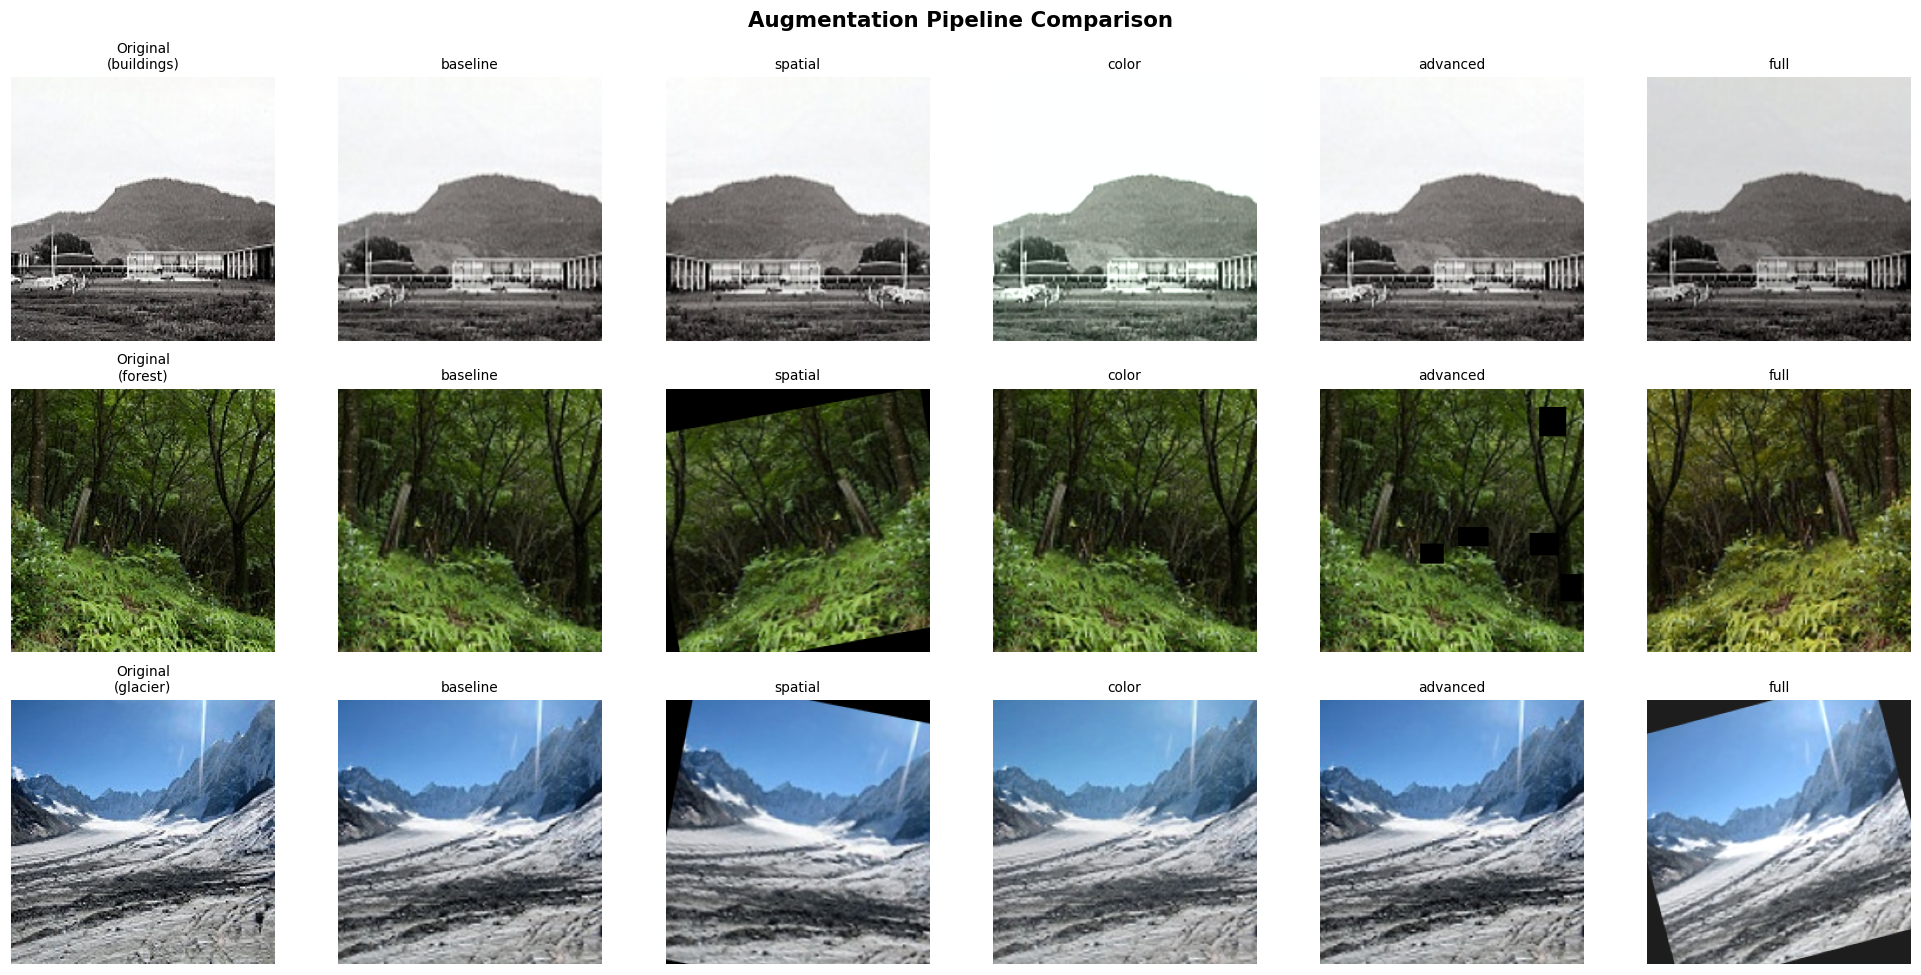

✅ Augmentation comparison saved to Google Drive


In [36]:
# Show the same image under each augmentation pipeline
sample_images = []
sample_labels = []
for cls_name in class_names[:3]:  # Show 3 classes
    cls_dir = train_dir / cls_name
    img_path = sorted(cls_dir.glob('*'))[0]
    img = np.array(Image.open(img_path).convert('RGB'))
    sample_images.append(img)
    sample_labels.append(cls_name)

n_pipelines = len(pipelines)
n_images = len(sample_images)

fig, axes = plt.subplots(n_images, n_pipelines + 1,
                         figsize=(3 * (n_pipelines + 1), 3 * n_images))

# Column 0: Original
for i, (img, label) in enumerate(zip(sample_images, sample_labels)):
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f'Original\n({label})', fontsize=9)
    axes[i, 0].axis('off')

# Columns 1+: Each pipeline
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)

for j, (name, pipeline) in enumerate(pipelines.items(), start=1):
    for i, img in enumerate(sample_images):
        augmented = pipeline(image=img.copy())['image']
        display = augmented.float() * std + mean
        display = display.permute(1, 2, 0).numpy()
        display = np.clip(display, 0, 1)
        axes[i, j].imshow(display)
        axes[i, j].set_title(name, fontsize=9)
        axes[i, j].axis('off')

plt.suptitle('Augmentation Pipeline Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'day4_augmentation_comparison.png'), dpi=120,
            bbox_inches='tight')
plt.show()
print('✅ Augmentation comparison saved to Google Drive')

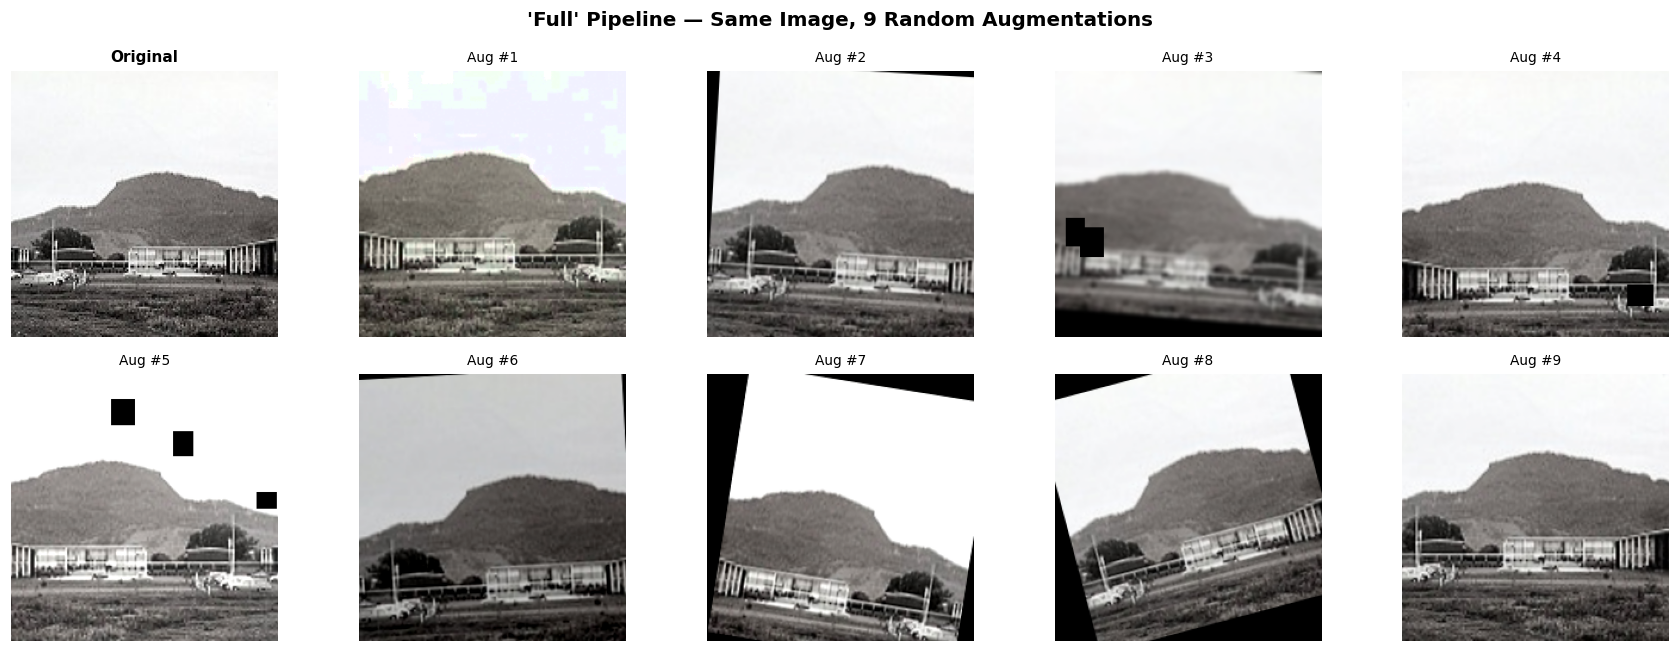

✅ Diversity plot saved


In [37]:
# Show 9 random augmented versions of the SAME image using the 'full' pipeline
# This demonstrates how much variety a single image can produce

cls_dir = train_dir / class_names[0]
img_path = sorted(cls_dir.glob('*'))[0]
original = np.array(Image.open(img_path).convert('RGB'))

fig, axes = plt.subplots(2, 5, figsize=(16, 6))
axes_flat = axes.flat

# First: original
axes_flat[0].imshow(original)
axes_flat[0].set_title('Original', fontsize=10, fontweight='bold')
axes_flat[0].axis('off')

# Rest: augmented
full_pipeline = pipelines['full']
for i in range(1, 10):
    augmented = full_pipeline(image=original.copy())['image']
    display = augmented.float() * std + mean
    display = display.permute(1, 2, 0).numpy()
    display = np.clip(display, 0, 1)
    axes_flat[i].imshow(display)
    axes_flat[i].set_title(f'Aug #{i}', fontsize=9)
    axes_flat[i].axis('off')

plt.suptitle("'Full' Pipeline — Same Image, 9 Random Augmentations",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'day4_full_diversity.png'), dpi=120,
            bbox_inches='tight')
plt.show()
print('✅ Diversity plot saved')

## 5 · Dataset Wrapper & DataLoaders

### The key integration challenge

- **ImageFolder** returns `(PIL Image, label)`
- **Albumentations** expects `numpy.ndarray (H, W, C), uint8`
- **PyTorch model** expects `torch.Tensor (C, H, W), float32`

Our wrapper handles: `PIL → NumPy → Albumentations → Tensor`

In [38]:
class AlbumentationsDataset(Dataset):
    """Wraps an ImageFolder dataset to use Albumentations transforms."""

    def __init__(self, image_folder_dataset, albu_transform=None):
        self.dataset = image_folder_dataset
        self.albu_transform = albu_transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        pil_image, label = self.dataset[idx]
        image = np.array(pil_image)  # PIL → NumPy (H, W, C)
        if self.albu_transform:
            augmented = self.albu_transform(image=image)
            image = augmented['image']  # Now (C, H, W) tensor
        return image, label


class AlbumentationsSubsetDataset(Dataset):
    """Wraps a Subset (from random_split) with Albumentations transforms."""

    def __init__(self, subset, albu_transform=None):
        self.subset = subset
        self.albu_transform = albu_transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        pil_image, label = self.subset[idx]
        image = np.array(pil_image)
        if self.albu_transform:
            augmented = self.albu_transform(image=image)
            image = augmented['image']
        return image, label

print('✅ Dataset wrappers defined')

✅ Dataset wrappers defined


In [39]:
def build_loaders(train_transform, eval_transform,
                  batch_size=32, val_split=0.15, num_workers=2):
    """
    Build train/val/test DataLoaders with given transforms.
    Uses the SAME random split every time (seed=42).
    """
    # Load RAW datasets (no transforms)
    raw_train = ImageFolder(str(train_dir), transform=None)
    raw_test  = ImageFolder(str(test_dir),  transform=None)

    # Same split every experiment
    val_size   = int(len(raw_train) * val_split)
    train_size = len(raw_train) - val_size
    train_subset, val_subset = random_split(
        raw_train, [train_size, val_size],
        generator=torch.Generator().manual_seed(42),
    )

    # Wrap with Albumentations
    train_dataset = AlbumentationsSubsetDataset(train_subset, train_transform)
    val_dataset   = AlbumentationsSubsetDataset(val_subset,   eval_transform)
    test_dataset  = AlbumentationsDataset(raw_test, eval_transform)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                              num_workers=num_workers, pin_memory=True)
    val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False,
                              num_workers=num_workers, pin_memory=True)
    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False,
                              num_workers=num_workers, pin_memory=True)

    print(f'  Splits — Train: {train_size:,}  Val: {val_size:,}  Test: {len(raw_test):,}')
    return train_loader, val_loader, test_loader

print('✅ Loader builder ready')

✅ Loader builder ready


## 6 · Model Builder & Training Functions

Same architecture as Day 3 — ResNet-18 with full fine-tuning and two-LR strategy.

We keep this **identical** across all experiments. Only the training transforms change.

In [40]:
from tqdm.notebook import tqdm

def build_model(backbone_name='resnet18', num_classes=6):
    """Build a pretrained model with a fresh classifier head."""
    if backbone_name == 'resnet18':
        model = models.resnet18(weights=ResNet18_Weights.DEFAULT)
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Dropout(p=0.3),
            nn.Linear(in_features, num_classes),
        )
    elif backbone_name == 'resnet50':
        model = models.resnet50(weights=ResNet50_Weights.DEFAULT)
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Dropout(p=0.3),
            nn.Linear(in_features, num_classes),
        )
    elif backbone_name == 'efficientnet_b0':
        model = models.efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
        in_features = model.classifier[-1].in_features
        model.classifier[-1] = nn.Sequential(
            nn.Dropout(p=0.3),
            nn.Linear(in_features, num_classes),
        )
    else:
        raise ValueError(f'Unknown backbone: {backbone_name}')

    return model.to(DEVICE)


def train_one_epoch(model, loader, criterion, optimizer, epoch_idx=None, total_epochs=None):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    # Add nice description to tqdm
    desc = f"Epoch {epoch_idx}/{total_epochs}" if (epoch_idx and total_epochs) else "Training"
    pbar = tqdm(loader, desc=desc, leave=False)

    for imgs, labels in pbar:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        out = model(imgs)
        loss = criterion(out, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * imgs.size(0)
        _, pred = out.max(1)
        total += labels.size(0)
        correct += pred.eq(labels).sum().item()

        # Update live metrics on progress bar
        pbar.set_postfix({
            'loss': f"{loss.item():.3f}",
            'acc': f"{100.0 * correct / total:.1f}%"
        })

    return total_loss / total, 100.0 * correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, desc="Evaluating"):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []

    pbar = tqdm(loader, desc=desc, leave=False)
    for imgs, labels in pbar:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        out = model(imgs)
        loss = criterion(out, labels)

        total_loss += loss.item() * imgs.size(0)
        _, pred = out.max(1)
        total += labels.size(0)
        correct += pred.eq(labels).sum().item()
        all_preds.extend(pred.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        pbar.set_postfix({
            'loss': f"{loss.item():.3f}",
            'acc': f"{100.0 * correct / total:.1f}%"
        })

    return (total_loss / total, 100.0 * correct / total,
            np.array(all_preds), np.array(all_labels))

print('✅ Model builder & training functions with live progress bars ready')

✅ Model builder & training functions with live progress bars ready


In [41]:
def run_experiment(exp_name, train_loader, val_loader, test_loader,
                   backbone_name='resnet18', epochs=10, lr=1e-3,
                   weight_decay=1e-4, wandb_run=None):
    """
    Run one ablation experiment.
    Full fine-tuning with two-LR strategy (backbone lr = head lr × 0.01).
    """
    print(f'\n{"─" * 60}')
    print(f'  Experiment: {exp_name.upper()}')
    print(f'  Backbone: {backbone_name}  |  Epochs: {epochs}')
    print(f'{"─" * 60}')

    model = build_model(backbone_name, num_classes)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'  Trainable params: {trainable:,}')

    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    # Two-LR: low for backbone, normal for head
    if 'resnet' in backbone_name:
        head_module = model.fc
    else:
        head_module = model.classifier[-1]

    head_param_ids = {id(p) for p in head_module.parameters()}
    backbone_params = [p for p in model.parameters()
                       if p.requires_grad and id(p) not in head_param_ids]
    head_params = list(head_module.parameters())

    optimizer = optim.AdamW([
        {'params': backbone_params, 'lr': lr * 0.01},
        {'params': head_params,     'lr': lr},
    ], weight_decay=weight_decay)

    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_val_acc = 0.0

    t_start = time.time()
    for epoch in range(1, epochs + 1):
        # Pass epoch tracking to train_one_epoch for nice progress bars
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, epoch, epochs)
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, desc="Evaluating Val")
        scheduler.step()

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        lr_now = optimizer.param_groups[0]['lr']
        print(f'  Ep {epoch:2d}/{epochs}  LR={lr_now:.2e}  '
              f'Train {train_loss:.3f}/{train_acc:.1f}%  '
              f'Val {val_loss:.3f}/{val_acc:.1f}%')

        if wandb_run:
            wandb_run.log({
                f'{exp_name}/epoch': epoch,
                f'{exp_name}/train_loss': train_loss,
                f'{exp_name}/train_acc': train_acc,
                f'{exp_name}/val_loss': val_loss,
                f'{exp_name}/val_acc': val_acc,
                f'{exp_name}/lr': lr_now,
            })

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            save_path = os.path.join(MODEL_DIR, f'day4_{backbone_name}_{exp_name}.pt')
            torch.save(model.state_dict(), save_path)

    elapsed = time.time() - t_start
    print(f'\n  Best val acc: {best_val_acc:.1f}%  ({elapsed:.0f}s)')

    # Final test evaluation
    best_path = os.path.join(MODEL_DIR, f'day4_{backbone_name}_{exp_name}.pt')
    if os.path.exists(best_path):
        model.load_state_dict(torch.load(best_path, weights_only=True))
    test_loss, test_acc, test_preds, test_labels = evaluate(
        model, test_loader, criterion, desc="Evaluating Test"
    )
    print(f'  Test acc: {test_acc:.1f}%')

    # Per-class accuracy
    per_class_acc = {}
    for i, cls in enumerate(class_names):
        mask = test_labels == i
        if mask.sum() > 0:
            cls_acc = 100.0 * (test_preds[mask] == i).sum() / mask.sum()
            per_class_acc[cls] = float(cls_acc)
            print(f'    {cls:<15} {cls_acc:.1f}%')

    if wandb_run:
        wandb_run.log({f'{exp_name}/test_acc': test_acc})

    return {
        'exp_name': exp_name,
        'best_val_acc': best_val_acc,
        'test_acc': test_acc,
        'per_class_acc': per_class_acc,
        'train_time_s': elapsed,
        'history': history,
    }

print('Experiment runner ready')

Experiment runner ready


## 7 · Run the Ablation Study

⏱ **This will take ~60–90 minutes** (5 experiments × ~15 min each on T4 GPU).

Each experiment:
1. Builds fresh DataLoaders with its specific training transform
2. Creates a fresh model (same architecture, same pretrained weights)
3. Trains for the same number of epochs with the same hyperparameters
4. Evaluates on the same test set with the same eval transform

In [ ]:
# ── Hyperparameters (same for ALL experiments) ─────────────────────
BACKBONE   = 'resnet18'
EPOCHS     = 10
BATCH_SIZE = 32
LR         = 1e-3
WEIGHT_DECAY = 1e-4
VAL_SPLIT  = 0.15

# ── Optional: W&B logging ────────────────────────────────────────
# Set USE_WANDB = True after running: !wandb login
USE_WANDB   = False
wandb_run   = None
if USE_WANDB and WANDB_AVAILABLE:
    wandb_run = wandb.init(
        project='cv-week2-augmentation',
        name=f'day4-ablation-{BACKBONE}',
        config={'backbone': BACKBONE, 'epochs': EPOCHS,
                'batch_size': BATCH_SIZE, 'lr': LR,
                'weight_decay': WEIGHT_DECAY, 'val_split': VAL_SPLIT},
    )
    print(f'W&B run started: {wandb_run.url}')

all_results = []

for exp_name, train_transform in pipelines.items():
    print(f'\n{"━" * 60}')
    print(f'  STARTING EXPERIMENT: {exp_name.upper()}')
    print(f'{"━" * 60}')

    # Fresh DataLoaders for this experiment
    train_loader, val_loader, test_loader = build_loaders(
        train_transform=train_transform,
        eval_transform=eval_transform,
        batch_size=BATCH_SIZE,
        val_split=VAL_SPLIT,
        num_workers=2,
    )

    result = run_experiment(
        exp_name=exp_name,
        train_loader=train_loader,
        val_loader=val_loader,
        test_loader=test_loader,
        backbone_name=BACKBONE,
        epochs=EPOCHS,
        lr=LR,
        weight_decay=WEIGHT_DECAY,
        wandb_run=wandb_run,
    )
    all_results.append(result)

if wandb_run:
    wandb_run.summary.update({
        'best_experiment': max(all_results, key=lambda x: x['test_acc'])['exp_name'],
        'best_test_acc': max(r['test_acc'] for r in all_results),
        'baseline_test_acc': all_results[0]['test_acc'],
    })
    wandb_run.finish()
    print('W&B run finished')

print(f'All {len(all_results)} experiments complete!')


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  STARTING EXPERIMENT: BASELINE
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Splits — Train: 11,930  Val: 2,105  Test: 3,001

────────────────────────────────────────────────────────────
  Experiment: BASELINE
  Backbone: resnet18  |  Epochs: 10
────────────────────────────────────────────────────────────
  Trainable params: 11,179,590


Epoch 1/10:   0%|          | 0/373 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


## 8 · Ablation Results Table

In [ ]:
# ── Print the ablation table ──────────────────────────────────────
print('\n' + '=' * 70)
print('ABLATION RESULTS TABLE')
print('=' * 70)
print(f'{"Experiment":<15} {"Val Acc":>10} {"Test Acc":>10} '
      f'{"Δ vs Base":>10} {"Time (s)":>10}')
print('-' * 57)

baseline_test = all_results[0]['test_acc']

for r in all_results:
    delta = r['test_acc'] - baseline_test
    delta_str = f'{delta:+.1f}%' if r['exp_name'] != 'baseline' else '—'
    print(f'{r["exp_name"]:<15} {r["best_val_acc"]:>9.1f}% '
          f'{r["test_acc"]:>9.1f}% {delta_str:>10} {r["train_time_s"]:>9.0f}')

print('-' * 57)

# Winner
best = max(all_results, key=lambda x: x['test_acc'])
print(f'\n✅ Best on test set: {best["exp_name"]} ({best["test_acc"]:.1f}%)')

if best['exp_name'] == 'baseline':
    print('⚠️  Augmentation did NOT help! Possible reasons:')
    print('   - Dataset may be large/diverse enough already')
    print('   - Augmentations may be too aggressive')
    print('   - May need more epochs for augmented models to converge')
else:
    improvement = best['test_acc'] - baseline_test
    print(f'↑  Improvement over baseline: +{improvement:.1f}%')

## 9 · Training Curves & Per-Class Comparison

In [ ]:
# ── Training curves (all experiments on same axes) ────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'Day 4 Ablation — {BACKBONE.upper()}', fontsize=14)

colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974']

for i, (metric, ylabel) in enumerate([('acc', 'Accuracy (%)'), ('loss', 'Loss')]):
    ax = axes[i]
    for j, r in enumerate(all_results):
        epochs_range = range(1, len(r['history'][f'val_{metric}']) + 1)
        color = colors[j % len(colors)]
        ax.plot(epochs_range, r['history'][f'val_{metric}'],
                color=color, label=r['exp_name'], linewidth=2)
        ax.plot(epochs_range, r['history'][f'train_{metric}'],
                color=color, linestyle='--', alpha=0.4)
    ax.set_xlabel('Epoch')
    ax.set_ylabel(ylabel)
    ax.set_title(f'Validation {ylabel} (solid) / Train (dashed)')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, f'day4_{BACKBONE}_ablation_curves.png'), dpi=120)
plt.show()
print('✅ Ablation curves saved')

In [ ]:
# ── Per-class accuracy comparison across experiments ──────────────
n_cls = len(class_names)
n_exp = len(all_results)
x = np.arange(n_cls)
width = 0.8 / n_exp

fig, ax = plt.subplots(figsize=(14, 6))

for j, r in enumerate(all_results):
    accs = [r['per_class_acc'].get(cls, 0) for cls in class_names]
    ax.bar(x + j * width, accs, width, label=r['exp_name'],
           color=colors[j % len(colors)], alpha=0.85)

ax.set_xlabel('Class')
ax.set_ylabel('Test Accuracy (%)')
ax.set_title(f'Per-Class Accuracy — Augmentation Ablation ({BACKBONE.upper()})')
ax.set_xticks(x + width * (n_exp - 1) / 2)
ax.set_xticklabels(class_names, rotation=30, ha='right')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, f'day4_{BACKBONE}_per_class_comparison.png'),
            dpi=120)
plt.show()
print('✅ Per-class comparison saved')

## 10 · Save Results to Google Drive

In [ ]:
# ── Save results JSON ─────────────────────────────────────────────
results_json = {
    'dataset': 'Intel Image Classification',
    'backbone': BACKBONE,
    'epochs': EPOCHS,
    'num_classes': num_classes,
    'class_names': class_names,
    'experiments': [
        {
            'name': r['exp_name'],
            'best_val_acc': r['best_val_acc'],
            'test_acc': r['test_acc'],
            'per_class_acc': r['per_class_acc'],
            'train_time_s': r['train_time_s'],
        }
        for r in all_results
    ],
}

results_path = os.path.join(RESULTS_DIR, f'day4_{BACKBONE}_ablation_results.json')
with open(results_path, 'w') as f:
    json.dump(results_json, f, indent=2)

print(f'Results JSON → {results_path}')
print(f'\n✅ Day 4 complete!')
print(f'   Next: Day 5 — Full ablation study with confusion matrix & per-class metrics')

## 📝 Summary & Key Takeaways

### What we learned today

1. **Albumentations** is faster and more flexible than torchvision transforms
2. **Always start with a no-augmentation baseline** — you can't measure improvement without a reference
3. **Controlled experiments** mean changing ONLY one variable at a time (the augmentation pipeline)
4. **Not all augmentations help** — some can hurt, and that's a valid finding
5. **Domain knowledge matters** — VerticalFlip makes sense for satellite images but not for outdoor scenes

### Files saved to Google Drive
- `results/day4_augmentation_comparison.png` — visual comparison of all pipelines
- `results/day4_full_diversity.png` — same image, multiple augmentations
- `results/day4_resnet18_ablation_curves.png` — training curves
- `results/day4_resnet18_per_class_comparison.png` — per-class accuracy bars
- `results/day4_resnet18_ablation_results.json` — full results JSON
- `models/day4_resnet18_*.pt` — best checkpoints per experiment

### What's next (Day 5)
- Run the final augmentation ablation with confusion matrices
- Compute per-class metrics (precision, recall, F1)
- Write the results README for the week
- Compare everything: baseline CNN vs feature extraction vs fine-tuned vs augmented